# BloodMNIST data audit and fixed 1% subset

This notebook audits the official BloodMNIST split labels, creates the required training/validation class-count and prevalence table, and saves a fixed, class-stratified 1% training subset.

> **Test-set protection:** this notebook records only the number of test images. It does not read or report test labels.

The compact official BloodMNIST source file is used for the audit. Its split membership and labels are the same as the 224×224 release; model training will resize images to 224×224 later.

## Before running

From the repository root, prepare the runtime once:

```bash
nix develop
./scripts/setup-runtime
./scripts/jupyter
```

Open this notebook in JupyterLab and select **Python (BloodMNIST ResNet)**.

In [16]:
from pathlib import Path
from collections import Counter
import csv
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from medmnist import INFO, BloodMNIST

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "README.md").is_file() and (candidate / "flake.nix").is_file():
            return candidate
    raise RuntimeError(
        "Could not find the project root. Open this notebook from the project repository."
    )

PROJECT_ROOT = find_project_root(Path.cwd().resolve())

AUDIT_SIZE = 28
DATA_ROOT = PROJECT_ROOT / ".data" / "medmnist"
OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "data_audit"
SUBSET_PATH = PROJECT_ROOT / "splits" / "bloodmnist_train_1pct_seed2026.npz"
SEED = 2026
SUBSET_FRACTION = 0.01

names = {int(key): value for key, value in INFO["bloodmnist"]["label"].items()}
def counts_and_prevalence(labels):
    values = labels.reshape(-1).astype(int)
    counts = Counter(values.tolist())
    total = len(values)
    return [
        {"class_index": index, "class_name": names[index], "count": counts[index],
         "prevalence_percent": 100 * counts[index] / total}
        for index in sorted(names)
    ]

def stratified_subset_indices(labels, fraction, seed):
    values = labels.reshape(-1).astype(int)
    target_size = round(len(values) * fraction)
    classes, class_counts = np.unique(values, return_counts=True)
    exact = class_counts * fraction
    allocations = np.floor(exact).astype(int)
    remainders = np.argsort(-(exact - allocations), kind="stable")
    allocations[remainders[:target_size - allocations.sum()]] += 1
    rng = np.random.default_rng(seed)
    sampled = [
        rng.choice(np.flatnonzero(values == class_index), size=allocation, replace=False)
        for class_index, allocation in zip(classes, allocations, strict=True)
    ]
    return np.sort(np.concatenate(sampled))

print(f"Project root: {PROJECT_ROOT}")
print("Audit source resolution: 28×28; training resolution later: 224×224")

Project root: /home/james/Chula/deep_learning_term_project
Audit source resolution: 28×28; training resolution later: 224×224


In [17]:
DATA_ROOT.mkdir(parents=True, exist_ok=True)
datasets = {
    split: BloodMNIST(split=split, size=AUDIT_SIZE, root=DATA_ROOT, download=True)
    for split in ("train", "val", "test")
}
train, val, test = datasets["train"], datasets["val"], datasets["test"]

if train.imgs.ndim != 4 or train.imgs.shape[-1] != 3:
    raise ValueError(f"Expected RGB images; received {train.imgs.shape}.")
if set(np.unique(train.labels.astype(int))) != set(names):
    raise ValueError("Training labels do not match the documented eight classes.")

print(f"Training images:   {len(train):,}")
print(f"Validation images: {len(val):,}")
print(f"Test images:       {len(test):,} (labels not inspected)")
print(f"Stored image shape: {train.imgs.shape[1:]}")
print(f"labels shape: {train.labels.shape}")

Training images:   11,959
Validation images: 1,712
Test images:       3,421 (labels not inspected)
Stored image shape: (28, 28, 3)
labels shape: (11959, 1)


In [18]:
train_rows = counts_and_prevalence(train.labels)
val_rows = counts_and_prevalence(val.labels)

counts_table = pd.DataFrame({
    "Class": [row["class_name"] for row in train_rows],
    "Training count": [row["count"] for row in train_rows],
    "Training prevalence (%)": [row["prevalence_percent"] for row in train_rows],
    "Validation count": [row["count"] for row in val_rows],
    "Validation prevalence (%)": [row["prevalence_percent"] for row in val_rows],
})
counts_table.loc[len(counts_table)] = ["Total", len(train), 100.0, len(val), 100.0]
counts_table.style.format({
    "Training count": "{:,}", "Training prevalence (%)": "{:.2f}",
    "Validation count": "{:,}", "Validation prevalence (%)": "{:.2f}",
})

,Class,Training count,Training prevalence (%),Validation count,Validation prevalence (%)
0,basophil,852,7.12,122,7.13
1,eosinophil,"2,181",18.24,312,18.22
2,erythroblast,"1,085",9.07,155,9.05
3,"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)","2,026",16.94,290,16.94
4,lymphocyte,849,7.10,122,7.13
5,monocyte,993,8.30,143,8.35
6,neutrophil,"2,330",19.48,333,19.45
7,platelet,"1,643",13.74,235,13.73
8,Total,"11,959",100.00,"1,712",100.00


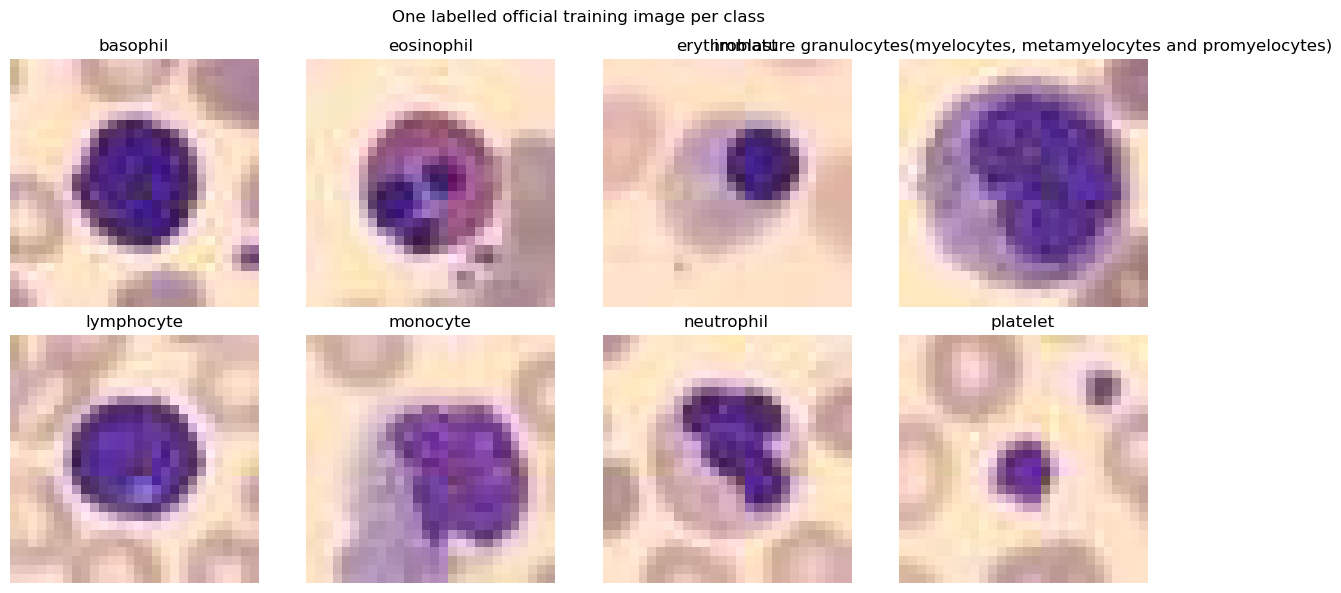

In [19]:
labels = train.labels.reshape(-1).astype(int)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for class_index, axis in enumerate(axes.flat):
    image_index = int(np.flatnonzero(labels == class_index)[0])
    image, _ = train[image_index]
    axis.imshow(image)
    axis.set_title(names[class_index])
    axis.axis("off")
fig.suptitle("One labelled official training image per class")
fig.tight_layout()

In [ ]:
subset_indices = stratified_subset_indices(train.labels, SUBSET_FRACTION, SEED)
subset_rows = counts_and_prevalence(train.labels[subset_indices])
subset_table = pd.DataFrame(subset_rows)[["class_name", "count", "prevalence_percent"]]
subset_table.columns = ["Class", "1% subset count", "Prevalence (%)"]
subset_table.style.format({"1% subset count": "{:,}", "Prevalence (%)": "{:.2f}"})

In [ ]:
# Run only after reviewing the tables above.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUBSET_PATH.parent.mkdir(parents=True, exist_ok=True)

for rows, filename in [
    (train_rows, "train_class_counts.csv"),
    (val_rows, "val_class_counts.csv"),
    (subset_rows, "train_1pct_class_counts.csv"),
]:
    with (OUTPUT_DIR / filename).open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

markdown_lines = [
    "# BloodMNIST Official Split Counts", "",
    "Generated by `notebooks/01_data_audit_and_subset.ipynb`. Prevalence is calculated within each split.", "",
    "| Class | Training count | Training prevalence | Validation count | Validation prevalence |",
    "| --- | ---: | ---: | ---: | ---: |",
]
for training_row, validation_row in zip(train_rows, val_rows, strict=True):
    markdown_lines.append(
        f"| {training_row['class_name']} | {training_row['count']:,} | {training_row['prevalence_percent']:.2f}% "
        f"| {validation_row['count']:,} | {validation_row['prevalence_percent']:.2f}% |"
    )
markdown_lines.extend([
    f"| **Total** | **{len(train):,}** | **100.00%** | **{len(val):,}** | **100.00%** |", "",
    f"**Test split total:** {len(test):,} images. Test labels were not inspected.",
])
(OUTPUT_DIR / "official_split_counts.md").write_text("\n".join(markdown_lines) + "\n")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for class_index, axis in enumerate(axes.flat):
    image_index = int(np.flatnonzero(labels == class_index)[0])
    image, _ = train[image_index]
    axis.imshow(image)
    axis.set_title(names[class_index])
    axis.axis("off")
fig.suptitle("One labelled official training image per class")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "labelled_training_samples.png", dpi=160)
plt.close(fig)

np.savez_compressed(
    SUBSET_PATH, indices=subset_indices, seed=np.array(SEED),
    fraction=np.array(SUBSET_FRACTION), source_split=np.array("train"),
    source_size=np.array(len(train)),
)
summary = {
    "dataset": "BloodMNIST", "source_resolution": [28, 28], "training_resolution": [224, 224],
    "channels": 3, "class_names": names,
    "official_split_sizes": {"train": len(train), "validation": len(val), "test": len(test)},
    "test_labels_inspected": False,
    "subset": {"source_split": "train", "fraction": SUBSET_FRACTION, "seed": SEED,
               "size": len(subset_indices), "indices_file": str(SUBSET_PATH.relative_to(PROJECT_ROOT))},
}
(OUTPUT_DIR / "audit_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print(f"Saved counts table: {OUTPUT_DIR / 'official_split_counts.md'}")
print(f"Saved subset:       {SUBSET_PATH} ({len(subset_indices)} images)")

## Completion checklist

After saving the artifacts, update `progress_tracker.md` to mark the data audit, required count tables, and fixed 1% subset as complete. Commit the notebook, `artifacts/data_audit/official_split_counts.md`, and `splits/bloodmnist_train_1pct_seed2026.npz`. Do **not** commit `.data/`, `.venv/`, or generated CSV/JSON/image artifacts.